In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd


In [2]:
def sample_shaft_inputs(n_samples: int, seed: int = 100):
    rng = np.random.default_rng(seed)

    # Step 1: independent samp ling
    d = rng.uniform(20, 150, size = n_samples)          
    Syt = rng.uniform(250, 1250, size=n_samples)
    phi = rng.uniform(0, 90, size = n_samples) 
    phi_rad = np.deg2rad(phi)        
    n_target = np.exp(rng.normal(0, 0.4, size = n_samples))  
     
    
        

    # Step 2: r nikaalo formula se
    r = Syt / (n_target * np.sqrt((np.cos(phi_rad))**2 + 3*(np.sin(phi_rad))**2)) 
    r = np.clip(r, None, 2 * Syt)        
    # Step 3: sigma, tau
    sigma = r * np.cos(phi_rad)       
    tau = r * np.sin(phi_rad)         

    # Step 4: back-calculate M, T (ye tera final feature hai)
    M = (sigma*np.pi*(d**3))/32          
    T = (tau*np.pi*(d**3))/16         

    return d, M, T, Syt
                                                                                        

In [3]:
d, M, T, Syt = sample_shaft_inputs(n_samples=5)
print(d.shape, M.shape, T.shape, Syt.shape)   # sab (5,) aana chahiye

sigma = 32*M/(np.pi*d**3)
tau = 16*T/(np.pi*d**3)
n_MDET_check = Syt / np.sqrt(sigma**2 + 3*tau**2)
print(n_MDET_check)

(5,) (5,) (5,) (5,)
[1.1390901  0.75908077 0.99210263 1.20913025 0.46188443]


In [4]:
def compute_labels(d, M, T,Syt, mu = 0.3):
    sigma = 32*M/(np.pi*(d**3))
    tau = 16*T/(np.pi*(d**3))

    sigma1 = sigma/2+np.sqrt((sigma/2)**2+ tau**2)
    sigma2 = sigma/2-np.sqrt((sigma/2)**2+ tau**2)

    n_MSST = Syt/np.sqrt(sigma**2+4*tau**2)
    n_MDET = Syt/np.sqrt(sigma**2+3*tau**2)
    n_MPST = Syt/(0.5*(sigma+np.sqrt(sigma**2+4*tau**2)))
    n_MPStT = Syt/(sigma1 - mu*sigma2)
    n_TStET = Syt/np.sqrt(sigma1**2+sigma2**2-2*mu*sigma1*sigma2)

    return n_MSST, n_MDET, n_MPST, n_MPStT, n_TStET

In [5]:
d, M, T, Syt = sample_shaft_inputs(n_samples=50000)
n_MSST, n_MDET, n_MPST, n_MPStT, n_TStET = compute_labels(d, M, T, Syt)

df = pd.DataFrame({
    'd': d, 'M': M, 'T': T, 'Syt': Syt,
    'n_MSST': n_MSST, 'n_MDET': n_MDET, 'n_MPST': n_MPST,
    'n_MPStT': n_MPStT, 'n_TStET': n_TStET
})

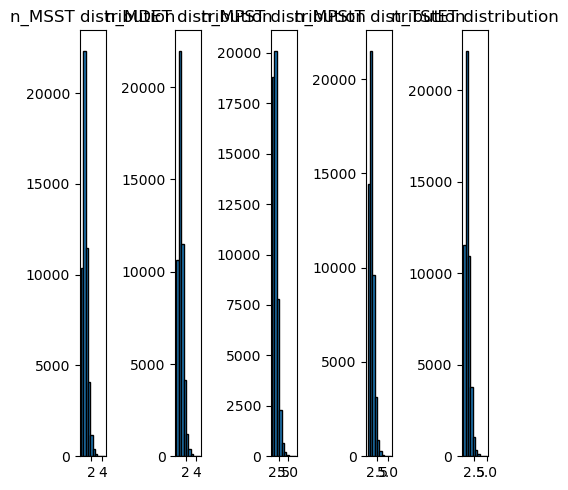

In [6]:
fig, axes = plt.subplots(1,5, figsize = (5,5))
axes[0].hist(df["n_MSST"], bins = 10, edgecolor = "black")
axes[0].set_title("n_MSST distribution")
axes[1].hist(df["n_MDET"], bins = 10,edgecolor = "black")
axes[1].set_title("n_MDET distribution")
axes[2].hist(df['n_MPST'], bins = 10,edgecolor = "black")
axes[2].set_title("n_MPST distribution")
axes[3].hist(df["n_MPStT"], bins = 10,edgecolor = "black")
axes[3].set_title("n_MPStT distribution")
axes[4].hist(df['n_TStET'], bins = 10,edgecolor = "black")
axes[4].set_title("n_TStET distribution")
plt.tight_layout()
plt.show()

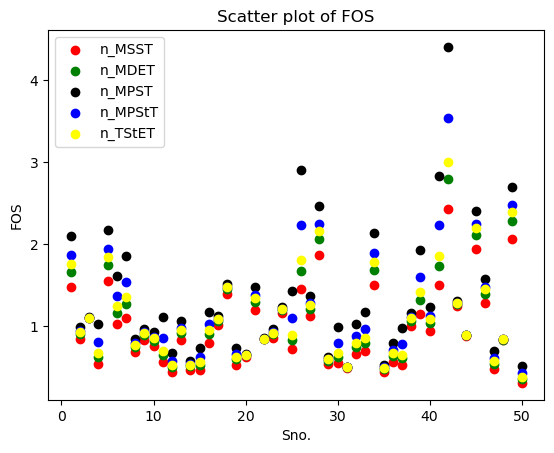

In [7]:
X = np.arange(1, 51,1)
plt.scatter(X, df["n_MSST"].head(50), c = "red", marker = "o", label = "n_MSST")
plt.scatter(X, df["n_MDET"].head(50), c = "green", marker = "o",label = "n_MDET" )
plt.scatter(X, df['n_MPST'].head(50), c = "black", marker = "o",label = "n_MPST" )
plt.scatter(X, df["n_MPStT"].head(50), c = "blue", marker = "o",label = "n_MPStT" )
plt.scatter(X, df['n_TStET'].head(50), c = "yellow", marker = "o",label = "n_TStET")
plt.xlabel("Sno.")
plt.ylabel("FOS")
plt.title("Scatter plot of FOS")
plt.legend()
plt.show()

In [8]:
# Class balance check — har theory ke liye
for col in ['n_MSST', 'n_MDET', 'n_MPST', 'n_MPStT', 'n_TStET']:
    fail_pct = (df[col] < 1).mean() * 100
    print(f"{col}: {fail_pct:.1f}% fail")

df.to_csv("data/shaft_failure.csv", index = False)
print(df.shape)

n_MSST: 59.0% fail
n_MDET: 49.8% fail
n_MPST: 29.7% fail
n_MPStT: 38.6% fail
n_TStET: 45.2% fail
(50000, 9)


In [9]:
#Invariant check
print((df['n_MDET'] >= df['n_MSST'] - 1e-9).all())


# print(df.describe())

print((df["M"]>2e8).sum())

True
1684


In [10]:
from sklearn.model_selection import train_test_split

X = df[['d', 'M', 'T', 'Syt']]
y = df['n_MDET']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))   
mae = mean_absolute_error(y_test, y_pred) 
   
r2 = r2_score(y_test, y_pred)     

print(f"RMSE: {rmse:.4f}, MAE: {mae:.4f}, R2: {r2:.4f}")

RMSE: 0.4010, MAE: 0.3016, R2: 0.1903


In [12]:
# Naya feature set banao — sigma, tau add karo raw d,M,T,Syt ke saath
df['sigma'] = 32*df['M'] / (np.pi * df['d']**3)
df['tau'] = 16*df['T'] / (np.pi * df['d']**3)

X2 = df[['sigma', 'tau', 'Syt']]   # d, M, T hata diye — sigma/tau unka saar hain
y2 = df['n_MDET']

X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=42)

model2 = LinearRegression()
model2.fit(X2_train, y2_train)
y2_pred = model2.predict(X2_test)

rmse = np.sqrt(mean_squared_error(y2_test, y2_pred))   
mae = mean_absolute_error(y2_test, y2_pred) 
   
r2 = r2_score(y2_test, y2_pred)     

print(f"RMSE: {rmse:.4f}, MAE: {mae:.4f}, R2: {r2:.4f}")

RMSE: 0.2773, MAE: 0.1904, R2: 0.6127


In [13]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)   # X_train = raw d,M,T,Syt wala, pehle wala

y_rf_pred = rf_model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_rf_pred))   
mae = mean_absolute_error(y_test, y_rf_pred) 
   
r2 = r2_score(y_test, y_rf_pred)       

print(f"RMSE: {rmse:.4f}, MAE: {mae:.4f}, R2: {r2:.4f}")



RMSE: 0.0851, MAE: 0.0493, R2: 0.9635


In [14]:
y_train_pred = rf_model.predict(X_train)
r2_train = r2_score(y_train, y_train_pred)
print(f"Train R2: {r2_train:.4f}, Test R2: {r2:.4f}")

Train R2: 0.9942, Test R2: 0.9635


In [15]:
importances = rf_model.feature_importances_
for feature, imp in zip(X_train.columns, importances):
    print(f"{feature}: {imp:.4f}")

d: 0.2696
M: 0.2125
T: 0.2797
Syt: 0.2382


In [16]:
y_test_class = (y_test < 1).astype(int)          
y_pred_class = (y_rf_pred < 1).astype(int)        
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
acc = accuracy_score(y_test_class, y_pred_class)   
print(confusion_matrix(y_test_class, y_pred_class))
print(classification_report(y_test_class, y_pred_class))

[[4953  130]
 [ 215 4702]]
              precision    recall  f1-score   support

           0       0.96      0.97      0.97      5083
           1       0.97      0.96      0.96      4917

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



In [17]:
wrong = (y_test_class != y_pred_class)        # boolean mask
fn_mask = (y_test_class == 1) & (y_pred_class == 0)   # TODO: actual fail (1) but predicted safe (0)

print(y_test[wrong].describe())
print(y_test[fn_mask].describe())    # sirf dangerous galtiyon ki true FoS

count    345.000000
mean       0.990552
std        0.037768
min        0.856449
25%        0.972706
50%        0.993090
75%        1.009390
max        1.093644
Name: n_MDET, dtype: float64
count    215.000000
mean       0.970153
std        0.029611
min        0.856449
25%        0.959049
50%        0.979752
75%        0.991513
max        0.999966
Name: n_MDET, dtype: float64


In [18]:
# --------------------------------------------------
# PART 1: Check boundary bias on the existing test set
# --------------------------------------------------

# y_rf_pred should be predictions for X_test
y_actual = np.asarray(y_test).reshape(-1)
y_pred = np.asarray(y_rf_pred).reshape(-1)

# Select actual target values near the boundary
band = (y_actual > 0.9) & (y_actual < 1.1)

if band.sum() > 0:
    bias = (y_pred[band] - y_actual[band]).mean()

    print("Boundary samples:", band.sum())
    print("Boundary bias:", bias)

    if bias > 0:
        print("Model has an upward bias near the boundary.")
    elif bias < 0:
        print("Model has a downward bias near the boundary.")
    else:
        print("No average boundary bias detected.")
else:
    print("No samples found in the boundary band.")


# --------------------------------------------------
# PART 2: Split training data into train and validation
# --------------------------------------------------

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

# Fit a fresh Random Forest only on the training split
rf = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_tr, y_tr)

# Predict on validation data
val_pred = np.asarray(rf.predict(X_val)).reshape(-1)
y_val_arr = np.asarray(y_val).reshape(-1)


# --------------------------------------------------
# PART 3: Threshold sweep
# --------------------------------------------------

# Actual Fail = target < 1
true_fail = y_val_arr < 1

print("\nThreshold | FN | FP | Predicted Fail")
print("-" * 43)

for t in np.arange(1.00, 1.15, 0.01):

    # Predicted Fail if predicted value is below threshold
    pred_fail = val_pred < t

    # False Negative: actual Fail, predicted Safe
    fn = np.sum(true_fail & ~pred_fail)

    # False Positive: actual Safe, predicted Fail
    fp = np.sum(~true_fail & pred_fail)

    predicted_fail_count = np.sum(pred_fail)

    print(
        f"{t:.2f}      | {fn:2d} | {fp:2d} | "
        f"{predicted_fail_count:3d}"
    )


Boundary samples: 2010
Boundary bias: 0.008525268840421388
Model has an upward bias near the boundary.

Threshold | FN | FP | Predicted Fail
-------------------------------------------
1.00      | 176 | 84 | 3885
1.01      | 127 | 118 | 3968
1.02      | 96 | 164 | 4045
1.03      | 73 | 224 | 4128
1.04      | 54 | 266 | 4189
1.05      | 38 | 327 | 4266
1.06      | 22 | 400 | 4355
1.07      | 18 | 465 | 4424
1.08      | 14 | 533 | 4496
1.09      | 10 | 592 | 4559
1.10      |  7 | 678 | 4648
1.11      |  6 | 754 | 4725
1.12      |  4 | 815 | 4788
1.13      |  2 | 894 | 4869
1.14      |  2 | 960 | 4935


In [19]:

import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# Set threshold
t = 1.10

# Convert regression predictions into binary classes
# Predicted value < 1.10 -> Fail (1)
# Predicted value >= 1.10 -> Safe (0)
y_pred_class_final = (np.asarray(y_rf_pred).reshape(-1) < t).astype(int)

# Actual classes: 1 = Fail, 0 = Safe
y_test_class_arr = np.asarray(y_test_class).reshape(-1)

# Confusion Matrix
cm = confusion_matrix(
    y_test_class_arr,
    y_pred_class_final,
    labels=[0, 1]
)

print("Threshold:", t)
print("\nConfusion Matrix:")
print(cm)

# Classification Report
print("\nClassification Report:")
print(
    classification_report(
        y_test_class_arr,
        y_pred_class_final,
        labels=[0, 1],
        target_names=["Safe (0)", "Fail (1)"],
        zero_division=0
    )
)

# Accuracy
print("Accuracy:", accuracy_score(
    y_test_class_arr,
    y_pred_class_final
))


Threshold: 1.1

Confusion Matrix:
[[4153  930]
 [  12 4905]]

Classification Report:
              precision    recall  f1-score   support

    Safe (0)       1.00      0.82      0.90      5083
    Fail (1)       0.84      1.00      0.91      4917

    accuracy                           0.91     10000
   macro avg       0.92      0.91      0.91     10000
weighted avg       0.92      0.91      0.91     10000

Accuracy: 0.9058


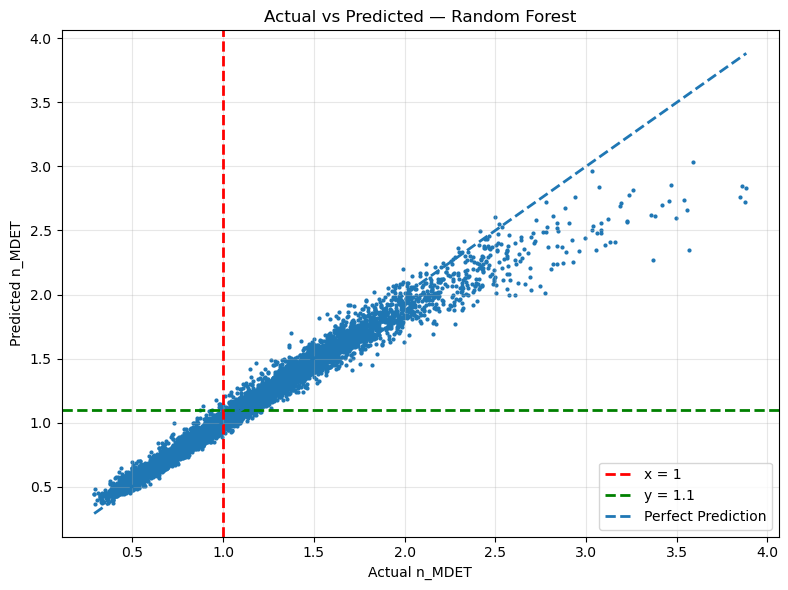

In [20]:

import numpy as np
import matplotlib.pyplot as plt

# Convert to 1D arrays
y_actual = np.asarray(y_test).reshape(-1)
y_pred = np.asarray(y_rf_pred).reshape(-1)

# Scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(y_actual, y_pred, s= 4)
# Vertical line: x = 1
plt.axvline(
    x=1,
    color="red",
    linestyle="--",
    linewidth=2,
    label="x = 1"
)

# Horizontal line: y = 1.1
plt.axhline(
    y=1.1,
    color="green",
    linestyle="--",
    linewidth=2,
    label="y = 1.1"
)
# Perfect prediction reference line
min_val = min(y_actual.min(), y_pred.min())
max_val = max(y_actual.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

# plt.xlim(0.8, 1.3)
# plt.ylim(0.8, 1.3)

plt.xlabel("Actual n_MDET")
plt.ylabel("Predicted n_MDET")
plt.title("Actual vs Predicted — Random Forest")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [21]:

import numpy as np
print(f"n_MDET max : {df['n_MDET'].max()}")

# Select validation samples in the Fail boundary band
fail_band = (y_val_arr > 0.9) & (y_val_arr < 1.0)

# Residual = predicted value - actual value
# Positive residual means the model predicted higher
resid = val_pred - y_val_arr

# Residual statistics in the Fail band
if fail_band.sum() > 0:
    fail_resid = resid[fail_band]

    print("Samples in Fail band:", fail_band.sum())
    print("Mean residual:", np.mean(fail_resid))
    print("Standard deviation:", np.std(fail_resid))
    print("99th percentile:", np.percentile(fail_resid, 99))
    print("99.5th percentile:", np.percentile(fail_resid, 99.5))
else:
    print("No samples found in the Fail band.")


n_MDET max : 4.717124183161373
Samples in Fail band: 822
Mean residual: 0.011791062411167121
Standard deviation: 0.0395413031735389
99th percentile: 0.12667069224394764
99.5th percentile: 0.1470080551467195


In [22]:

import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_predict

# Step 1: Generate out-of-fold predictions using 5-fold CV
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

oof_pred = cross_val_predict(
    rf,
    X_train,
    y_train,
    cv=5,
    n_jobs=1
)

# Step 2: Calculate residuals
y_train_arr = np.asarray(y_train).reshape(-1)
oof_pred = np.asarray(oof_pred).reshape(-1)

# Positive residual = model predicted higher than actual
oof_resid = oof_pred - y_train_arr

# Step 3: Select actual values near the Fail boundary
fail_band = (y_train_arr > 0.9) & (y_train_arr < 1.0)

fail_resid = oof_resid[fail_band]

if len(fail_resid) == 0:
    print("No samples found in the Fail boundary band.")
else:
    print("Samples in Fail band:", len(fail_resid))
    print("Mean residual:", np.mean(fail_resid))
    print("Standard deviation:", np.std(fail_resid))

    # Step 4: Evaluate thresholds from 1.05 to 1.15
    print("\nThreshold | Fraction above threshold")
    print("-" * 38)

    for t in np.arange(1.05, 1.151, 0.01):
        fraction = np.mean(fail_resid > (t - 1))
        print(f"{t:.2f}      | {fraction:.4f}")

    # Step 5: Residual percentiles
    p99 = np.percentile(fail_resid, 99)
    p995 = np.percentile(fail_resid, 99.5)

    print("\n99th percentile:", p99)
    print("99.5th percentile:", p995)

    # Convert residual percentiles to equivalent prediction thresholds
    print("\nEquivalent thresholds:")
    print("99th percentile threshold:", 1 + p99)
    print("99.5th percentile threshold:", 1 + p995)


Samples in Fail band: 4180
Mean residual: 0.013746690761995643
Standard deviation: 0.04080086669087244

Threshold | Fraction above threshold
--------------------------------------
1.05      | 0.1591
1.06      | 0.1132
1.07      | 0.0797
1.08      | 0.0577
1.09      | 0.0407
1.10      | 0.0301
1.11      | 0.0213
1.12      | 0.0158
1.13      | 0.0110
1.14      | 0.0079
1.15      | 0.0067

99th percentile: 0.1325685489068676
99.5th percentile: 0.15593256480818257

Equivalent thresholds:
99th percentile threshold: 1.1325685489068675
99.5th percentile threshold: 1.1559325648081826


In [23]:

import numpy as np

# Actual labels: 1 = Fail, 0 = Safe
true_fail = np.asarray(y_train).reshape(-1) < 1

# Threshold sweep from 1.05 to 1.15
for t in np.arange(1.05, 1.16, 0.01):

    # Predicted Fail if OOF prediction < threshold
    pred_fail = np.asarray(oof_pred).reshape(-1) < t

    # False Negatives: actual Fail, predicted Safe
    fn = np.sum(true_fail & ~pred_fail)

    # False Positives: actual Safe, predicted Fail
    fp = np.sum(~true_fail & pred_fail)

    # Error rates
    fnr = fn / true_fail.sum() if true_fail.sum() > 0 else 0
    fpr = fp / (~true_fail).sum() if (~true_fail).sum() > 0 else 0

    print(
        f"Threshold={t:.2f} | "
        f"FN={fn:5d} | FNR={fnr:.4%} | "
        f"FP={fp:5d} | FPR={fpr:.4%}"
    )


Threshold=1.05 | FN=  187 | FNR=0.9357% | FP= 1852 | FPR=9.2531%
Threshold=1.06 | FN=  135 | FNR=0.6755% | FP= 2187 | FPR=10.9268%
Threshold=1.07 | FN=  101 | FNR=0.5054% | FP= 2527 | FPR=12.6255%
Threshold=1.08 | FN=   73 | FNR=0.3653% | FP= 2873 | FPR=14.3542%
Threshold=1.09 | FN=   55 | FNR=0.2752% | FP= 3237 | FPR=16.1729%
Threshold=1.10 | FN=   40 | FNR=0.2002% | FP= 3619 | FPR=18.0814%
Threshold=1.11 | FN=   30 | FNR=0.1501% | FP= 3953 | FPR=19.7502%
Threshold=1.12 | FN=   21 | FNR=0.1051% | FP= 4302 | FPR=21.4939%
Threshold=1.13 | FN=   15 | FNR=0.0751% | FP= 4625 | FPR=23.1077%
Threshold=1.14 | FN=    8 | FNR=0.0400% | FP= 4995 | FPR=24.9563%
Threshold=1.15 | FN=    6 | FNR=0.0300% | FP= 5333 | FPR=26.6450%


In [24]:

import numpy as np
import pandas as pd

# 1. Identify False Negatives using final predictions
y_actual_class = np.asarray(y_test_class).reshape(-1)
y_final_class = np.asarray(y_pred_class_final).reshape(-1)

fn_mask = (y_actual_class == 1) & (y_final_class == 0)

# 2. Select FN rows from the original test features
if isinstance(X_test, pd.DataFrame):
    fn_df = X_test.loc[fn_mask, ["d", "M", "T", "Syt"]].copy()
else:
    fn_df = pd.DataFrame(
        np.asarray(X_test)[fn_mask],
        columns=["d", "M", "T", "Syt"]
    )

# 3. Add actual and predicted target values
fn_df["actual_n_MDET"] = np.asarray(y_test).reshape(-1)[fn_mask]
fn_df["predicted_n_MDET"] = np.asarray(y_rf_pred).reshape(-1)[fn_mask]

# 4. Use local variables to avoid overwriting global arrays
fn_d = fn_df["d"].to_numpy()
fn_M = fn_df["M"].to_numpy()
fn_T = fn_df["T"].to_numpy()

# 5. Calculate stresses (check that units are consistent)
fn_df["sigma"] = 32 * fn_M / (np.pi * fn_d**3)
fn_df["tau"] = 16 * fn_T / (np.pi * fn_d**3)

fn_df["tau/sigma"] = np.divide(
    fn_df["tau"].to_numpy(),
    fn_df["sigma"].to_numpy(),
    out=np.full(len(fn_df), np.nan),
    where=fn_df["sigma"].to_numpy() != 0
)

# 6. Sort by actual n_MDET
fn_df = fn_df.sort_values(
    "actual_n_MDET",
    ascending=True
).reset_index(drop=True)

print("Threshold used: 1.10")
print("Total False Negatives:", len(fn_df))

display(fn_df)


Threshold used: 1.10
Total False Negatives: 12


,d,M,T,Syt,actual_n_MDET,predicted_n_MDET,sigma,tau,tau/sigma
0,51.154485,2.255797e+06,3.591929e+06,254.378834,0.869990,1.101177,171.652035,136.661675,0.796155
1,50.413235,2.812821e+06,2.601104e+06,254.875435,0.889650,1.130384,223.618887,103.393728,0.462366
2,20.061411,3.947241e+05,5.804156e+05,772.427660,0.957994,1.179532,497.977123,366.121120,0.735217
3,20.099695,2.490451e+05,5.715715e+05,678.553814,0.976230,1.119557,312.399030,358.486030,1.147526
4,25.914687,7.367401e+05,1.063816e+06,675.698123,0.978676,1.142620,431.197795,311.314064,0.721975
5,20.346756,5.368442e+05,4.364060e+05,781.287124,0.984096,1.142649,649.176597,263.861093,0.406455
6,67.027379,8.059695e+06,9.398613e+06,381.822121,0.985452,1.120663,272.622676,158.956083,0.583063
7,76.681794,1.126867e+07,1.121174e+07,331.936088,0.987824,1.104288,254.563385,126.638649,0.497474
8,39.466523,3.378266e+06,3.226725e+06,722.055113,0.993947,1.114194,559.767061,267.328621,0.477571
9,119.122768,3.475793e+07,2.901284e+07,257.079436,0.994743,1.112085,209.444871,87.413002,0.417356


In [25]:

import numpy as np
import pandas as pd

# 1. Convert arrays to compatible formats
y_train_arr = np.asarray(y_train).reshape(-1)
oof_pred_arr = np.asarray(oof_pred).reshape(-1)

# 2. Select samples near the target boundary
band = (y_train_arr > 0.9) & (y_train_arr < 1.1)

# 3. Absolute residuals for selected samples
abs_resid = np.abs(oof_pred_arr - y_train_arr)

# 4. Build a DataFrame using original training features
if isinstance(X_train, pd.DataFrame):
    X_df = X_train[["Syt", "d", "M", "T"]].copy()
else:
    X_df = pd.DataFrame(
        np.asarray(X_train),
        columns=["d", "M", "T", "Syt"]
    )[["Syt", "d", "M", "T"]]

# Use local names; do not overwrite global arrays
band_df = X_df.loc[band, ["Syt", "d", "M", "T"]].copy()
band_df["abs_resid"] = abs_resid[band]

# 5. Calculate tau/sigma from bending moment and torque
band_d = band_df["d"].to_numpy()
band_M = band_df["M"].to_numpy()
band_T = band_df["T"].to_numpy()

band_sigma = 32 * band_M / (np.pi * band_d**3)
band_tau = 16 * band_T / (np.pi * band_d**3)

band_df["tau_sigma_ratio"] = np.divide(
    band_tau,
    band_sigma,
    out=np.full(len(band_df), np.nan),
    where=band_sigma != 0
)

# 6. Bin each feature into 5 quantile bins
features = ["Syt", "d", "tau_sigma_ratio"]

for feature in features:
    print(f"\n{'=' * 15} {feature} {'=' * 15}")

    # qcut may create fewer than 5 bins if values have many ties
    band_df[f"{feature}_bin"] = pd.qcut(
        band_df[feature],
        q=5,
        duplicates="drop"
    )

    summary = (
        band_df
        .dropna(subset=[f"{feature}_bin", "abs_resid"])
        .groupby(f"{feature}_bin", observed=True)["abs_resid"]
        .agg(
            count="count",
            mean_abs_resid="mean",
            percentile_95=lambda x: np.percentile(x, 95)
        )
    )

    print(summary.to_string())

print("\nTotal samples in boundary band:", len(band_df))



=============== Syt ===============
                      count  mean_abs_resid  percentile_95
Syt_bin                                                   
(250.289, 450.42]      1592        0.044919       0.128496
(450.42, 649.966]      1591        0.031247       0.084284
(649.966, 853.905]     1592        0.030464       0.080961
(853.905, 1049.772]    1591        0.027164       0.070949
(1049.772, 1249.968]   1592        0.029755       0.074633

=============== d ===============
                              count  mean_abs_resid  percentile_95
d_bin                                                             
(20.020999999999997, 44.638]   1592        0.044050       0.112819
(44.638, 70.631]               1591        0.034049       0.088373
(70.631, 98.149]               1592        0.030756       0.079384
(98.149, 123.867]              1591        0.027463       0.070482
(123.867, 149.999]             1592        0.027232       0.070619

=============== tau_sigma_ratio =============

model size: 100.4 MB
load check ok


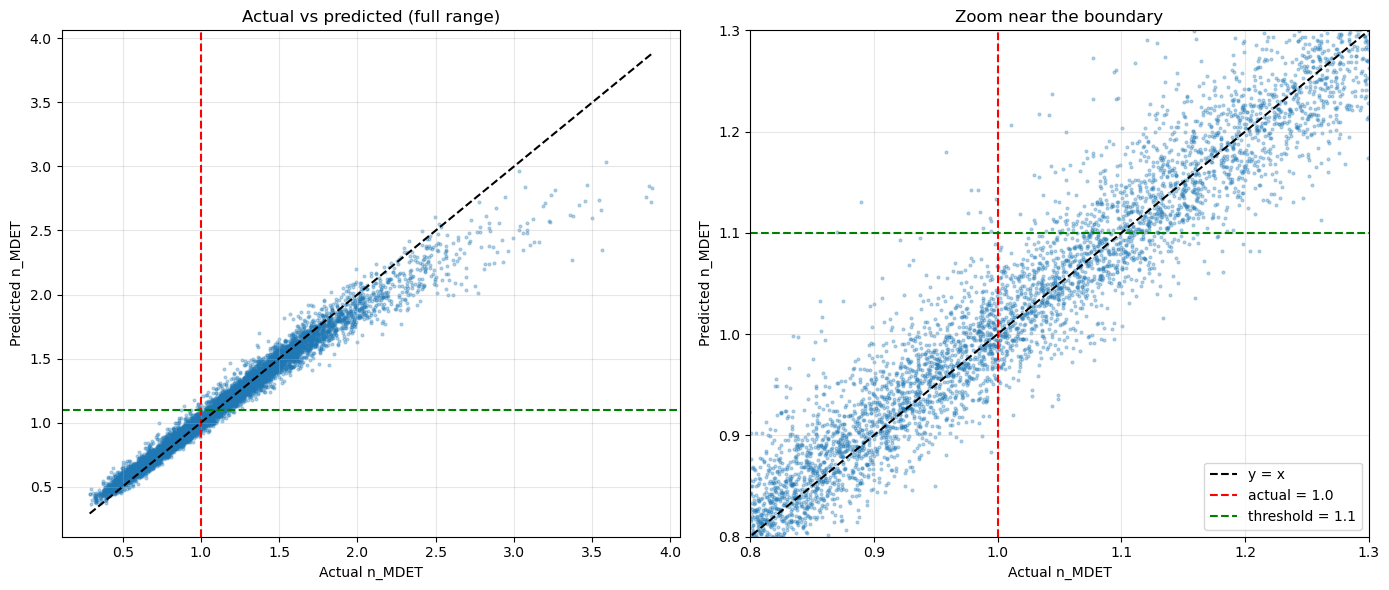

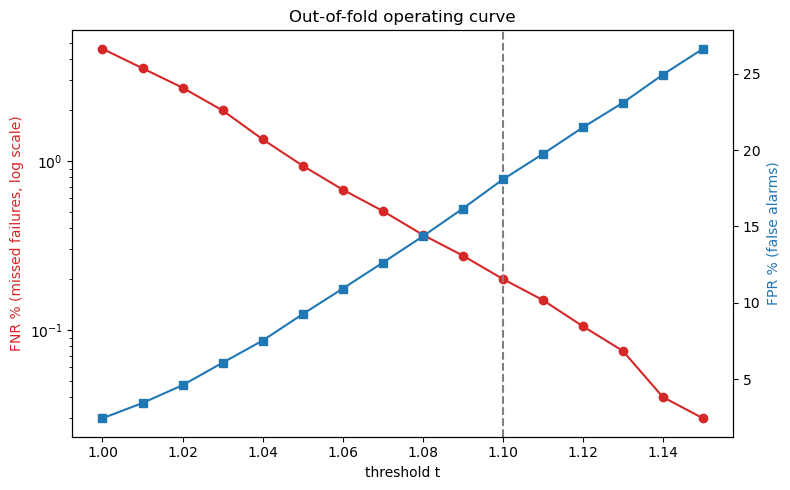

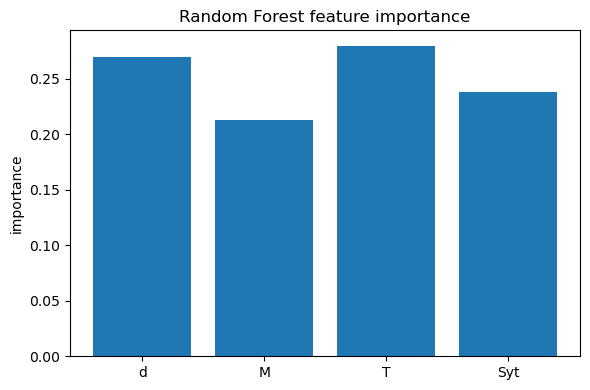

R2 linear (d, M, T, Syt)   : 0.1903
R2 linear (sigma, tau, Syt): 0.6127
R2 random forest           : 0.9635
t=1.00  TN=4953 FP=130 FN=215 TP=4702  fail recall=0.9563  FPR=0.0256  accuracy=0.9655
t=1.10  TN=4153 FP=930 FN=12 TP=4905  fail recall=0.9976  FPR=0.1830  accuracy=0.9058


In [27]:
# Paste each "# %%" block into its own notebook cell, run in order.
# Needs these variables from your notebook:
# rf_model, X_train, X_test, y_train, y_test, y_rf_pred, oof_pred,
# model (linear, raw), model2, X2_test, y2_test (linear, sigma/tau)

# %% 0. setup
import os
import json
import joblib
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

THRESHOLD = 1.10

os.makedirs("models", exist_ok=True)
os.makedirs("plots", exist_ok=True)

y_act = np.asarray(y_test).reshape(-1)
y_hat = np.asarray(y_rf_pred).reshape(-1)


# %% 1. save model and config
MODEL_PATH = "models/rf_mdet.joblib"
joblib.dump(rf_model, MODEL_PATH, compress=3)
print(f"model size: {os.path.getsize(MODEL_PATH) / 1e6:.1f} MB")

config = {
    "threshold": THRESHOLD,
    "seed": 42,
    "n_samples": 50000,
    "n_target_clip": [0.2, 5.0],
    "features": ["d", "M", "T", "Syt"],
    "target": "n_MDET",
}
with open("models/config.json", "w") as f:
    json.dump(config, f, indent=2)

# save/load check
loaded = joblib.load(MODEL_PATH)
assert np.allclose(loaded.predict(X_test), y_hat)
print("load check ok")


# %% 2. actual vs predicted (full range + zoom)
lo = min(y_act.min(), y_hat.min())
hi = max(y_act.max(), y_hat.max())

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, lim in zip(axes, [None, (0.8, 1.3)]):
    ax.scatter(y_act, y_hat, s=4, alpha=0.3)
    ax.plot([lo, hi], [lo, hi], "k--", lw=1.5, zorder=3, label="y = x")
    ax.axvline(1.0, color="red", ls="--", label="actual = 1.0")
    ax.axhline(THRESHOLD, color="green", ls="--", label=f"threshold = {THRESHOLD}")
    if lim:
        ax.set_xlim(lim)
        ax.set_ylim(lim)
    ax.set_xlabel("Actual n_MDET")
    ax.set_ylabel("Predicted n_MDET")
    ax.grid(alpha=0.3)
axes[0].set_title("Actual vs predicted (full range)")
axes[1].set_title("Zoom near the boundary")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.savefig("plots/actual_vs_predicted.png", dpi=150)
plt.show()


# %% 3. threshold curve from out-of-fold predictions
y_tr = np.asarray(y_train).reshape(-1)
oof = np.asarray(oof_pred).reshape(-1)
true_fail_tr = y_tr < 1

ts = np.round(np.arange(1.00, 1.16, 0.01), 2)
fnr, fpr = [], []
for t in ts:
    pred_fail = oof < t
    fnr.append((true_fail_tr & ~pred_fail).sum() / true_fail_tr.sum() * 100)
    fpr.append((~true_fail_tr & pred_fail).sum() / (~true_fail_tr).sum() * 100)

fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(ts, fnr, "o-", color="tab:red")
ax1.set_yscale("log")
ax1.set_xlabel("threshold t")
ax1.set_ylabel("FNR % (missed failures, log scale)", color="tab:red")
ax2 = ax1.twinx()
ax2.plot(ts, fpr, "s-", color="tab:blue")
ax2.set_ylabel("FPR % (false alarms)", color="tab:blue")
ax1.axvline(THRESHOLD, color="gray", ls="--")
ax1.set_title("Out-of-fold operating curve")
fig.tight_layout()
plt.savefig("plots/threshold_curve.png", dpi=150)
plt.show()


# %% 4. feature importance
plt.figure(figsize=(6, 4))
plt.bar(list(X_train.columns), rf_model.feature_importances_)
plt.ylabel("importance")
plt.title("Random Forest feature importance")
plt.tight_layout()
plt.savefig("plots/feature_importance.png", dpi=150)
plt.show()


# %% 5. numbers for the README (reporting only, do not tune on these)
print("R2 linear (d, M, T, Syt)   :", round(r2_score(y_test, model.predict(X_test)), 4))
print("R2 linear (sigma, tau, Syt):", round(r2_score(y2_test, model2.predict(X2_test)), 4))
print("R2 random forest           :", round(r2_score(y_act, y_hat), 4))

true_fail = y_act < 1
for t in (1.0, THRESHOLD):
    pred_fail = y_hat < t
    tp = (true_fail & pred_fail).sum()
    fn = (true_fail & ~pred_fail).sum()
    fp = (~true_fail & pred_fail).sum()
    tn = (~true_fail & ~pred_fail).sum()
    print(
        f"t={t:.2f}  TN={tn} FP={fp} FN={fn} TP={tp}  "
        f"fail recall={tp / (tp + fn):.4f}  FPR={fp / (fp + tn):.4f}  "
        f"accuracy={(tp + tn) / len(y_act):.4f}"
    )